# 02 – Aufteilung: Welche Blöcke dienen zum Lernen, Validieren und Testen?

**Ziel.** Die 691 Ausschnitte der Ground Truth in drei Gruppen teilen, **bevor** ein Netz gelernt hat:

| Gruppe | Wozu | Anteil |
| --- | --- | --- |
| **Lernen** | daraus lernt das Netz | 60 % |
| **Validieren** | Probeprüfung während des Lernens: beste Epoche und Schwelle wählen | 15 % |
| **Testen** | die eigentliche Prüfung, **einmal** am Schluss | 25 % |

**Warum.** Wie gross das Delta zwischen unserer Methode und den wirklichen Daten ist, lässt sich nur dort ehrlich messen, wo das Netz nie gelernt hat (`01b`, 8.1 K6). Darum werden die Testblöcke jetzt festgelegt und bis zum Schluss nicht angesehen.

**Warum ganze Blöcke?** Benachbarte Ausschnitte zeigen dieselbe Strasse, dieselben Autos, denselben Schatten. Lägen sie in verschiedenen Gruppen, sähe die Prüfung zu gut aus. Darum bleibt ein Block von 204,8 m (4 × 4 Ausschnitte) immer zusammen (`01b`, 7.3 und Abschnitt 11, E3).

**Eingaben:** `daten/ground_truth/ground_truth_hand.json` (Ausschnitte, Blöcke, Felder).
**Ausgaben:** `daten/verarbeitet/aufteilung.csv` (eine Zeile je Ausschnitt mit seiner Gruppe), Abbildung `02_aufteilung.png`.

In [1]:
import json                        # Einstellungen und Ground Truth lesen
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
ABB = ROOT / "ergebnisse" / "abbildungen"            # Abbildungen
HAND = ROOT / "daten" / "ground_truth" / "ground_truth_hand.json"   # Ground Truth des Auftraggebers (wird nur gelesen)

EINST = json.loads((ROOT / "einstellungen.json").read_text(encoding="utf-8"))   # Einstellungen aus Notebook 00
CRS, SEED = EINST["CRS"], EINST["SEED"]
print("Einstellungen aus Notebook 00: CRS =", CRS, "| Seed =", SEED)

import numpy as np                 # Zufall und Rechnen
import pandas as pd                # Tabellen
import geopandas as gpd            # Tabellen mit Geometrie
import matplotlib.pyplot as plt    # Abbildungen
from shapely.geometry import box   # Rechteck aus vier Koordinaten

Einstellungen aus Notebook 00: CRS = EPSG:2056 | Seed = 42


**Einstellungen dieses Schritts.** Sie stehen hier und werden in `einstellungen.json` abgelegt, damit spätere Notebooks dieselben Werte lesen.

| Einstellung | Wert | Warum |
| --- | --- | --- |
| `ANTEIL_LERNEN` | 0,60 | der grösste Teil, weil die Menge der Lernbeispiele der Engpass ist (`01b`, 8.4 V1) |
| `ANTEIL_VALIDIEREN` | 0,15 | genug, um Epoche und Schwelle zu wählen |
| Testen | Rest (0,25) | rund 15 Blöcke statt der vier Testzonen von Pilot 1 |
| `SCHICHTEN` | 3 | Blöcke mit wenigen, mittleren und vielen Feldern werden getrennt gezogen |

In [2]:
ANTEIL_LERNEN = 0.60
ANTEIL_VALIDIEREN = 0.15
SCHICHTEN = 3

EINST.update(ANTEIL_LERNEN=ANTEIL_LERNEN, ANTEIL_VALIDIEREN=ANTEIL_VALIDIEREN, SCHICHTEN=SCHICHTEN)   # zu den Einstellungen hinzufügen
(ROOT / "einstellungen.json").write_text(json.dumps(EINST, indent=2, ensure_ascii=False), encoding="utf-8")
print("Anteile: Lernen", ANTEIL_LERNEN, "| Validieren", ANTEIL_VALIDIEREN, "| Testen", round(1 - ANTEIL_LERNEN - ANTEIL_VALIDIEREN, 2))

Anteile: Lernen 0.6 | Validieren 0.15 | Testen 0.25


## 1. Ausschnitte, Blöcke und Felder lesen

**Schritt 1: Die Ground Truth lesen.** Die Datei enthält die Liste der Ausschnitte (jeder mit der Nummer seines Blocks) und die Liste der Felder. Zu jedem Feld bestimmen wir den Ausschnitt, in dem es liegt: Koordinate geteilt durch die Seitenlänge, abgerundet (`//`).

Vorher: eine Datei → nachher: eine Tabelle der Ausschnitte und eine Tabelle der gesetzten Felder.

In [3]:
erfasst = json.loads(HAND.read_text(encoding="utf-8"))             # einmal lesen; die Datei wird nicht verändert
KACHEL_M = erfasst["einstellungen"]["kachel_m"]                    # Seitenlänge eines Ausschnitts: 51,2 m
ausschnitte = pd.DataFrame(erfasst["kacheln"])[["id", "i", "j", "block", "status"]]   # eine Zeile je Ausschnitt
felder = pd.DataFrame(erfasst["felder"])                           # eine Zeile je Feld

assert (ausschnitte.status == "fertig").all()                      # die Erfassung ist abgeschlossen
felder = felder[~felder.geloescht & ~felder.verborgen].copy()      # gesetzte Felder: nicht gelöscht, nicht verborgen
felder["kachel"] = "k_" + (felder.x // KACHEL_M).astype(int).astype(str) + "_" + (felder.y // KACHEL_M).astype(int).astype(str)
print(f"Ausschnitte: {len(ausschnitte)} (alle abgeschlossen) in {ausschnitte.block.nunique()} Blöcken")
print(f"Gesetzte Felder: {len(felder)}")

Ausschnitte: 691 (alle abgeschlossen) in 62 Blöcken
Gesetzte Felder: 3278


**Schritt 2: Sichtbare Felder je Block zählen.** Die Blöcke sind sehr ungleich: Manche zeigen nur Wasser oder Dächer, andere über hundert Parkfelder. Für die Schichtung zählen wir je Block die Felder, die im Bild vom Frühjahr 2021 `sichtbar` sind (ohne Streifen, die nach `01b`, 8.2 W6, nicht zählen).

`map` schlägt zu jedem Feld den Block seines Ausschnitts nach; `value_counts` zählt je Block.

Vorher: Felder → nachher: eine Zeile je Block mit der Zahl seiner Ausschnitte und seiner sichtbaren Felder.

In [4]:
block_je_ausschnitt = ausschnitte.set_index("id").block            # Nachschlagetabelle: Ausschnitt -> Block
felder["block"] = felder.kachel.map(block_je_ausschnitt)           # Felder knapp neben einem Ausschnitt bekommen keinen Block
felder["zustand_2021"] = [zustand["2021"] for zustand in felder.zustand]       # Zustand im Bild 2021 als eigene Spalte
sichtbar_2021 = felder[(felder.zustand_2021 == "sichtbar") & (felder.form != "Streifen ohne Einzelfelder")]   # Maske und Auswahl

bloecke = ausschnitte.groupby("block").size().rename("ausschnitte").to_frame()           # Zahl der Ausschnitte je Block
bloecke["felder"] = sichtbar_2021.block.value_counts().reindex(bloecke.index).fillna(0).astype(int)   # sichtbare Felder je Block
print(f"Vorher: {len(sichtbar_2021)} sichtbare Felder → nachher: {len(bloecke)} Blöcke, zusammen {bloecke.felder.sum()} Felder")
print(f"Felder ohne Block (knapp neben einem Ausschnitt gesetzt): {int(felder.block.isna().sum())}")
bloecke.felder.describe().round(0).to_frame().T

Vorher: 2799 sichtbare Felder → nachher: 62 Blöcke, zusammen 2792 Felder
Felder ohne Block (knapp neben einem Ausschnitt gesetzt): 9


,count,mean,std,min,25%,50%,75%,max
felder,62.0,45.0,45.0,0.0,6.0,33.0,71.0,157.0


## 2. Die Ziehung

**Worum es geht.** Würden wir einfach 25 % der Blöcke zufällig zum Testen ziehen, könnten zufällig lauter leere oder lauter volle Blöcke in den Test fallen. Darum **Schichtung**: Die Blöcke werden nach der Zahl ihrer Felder sortiert und in drei gleich grosse Schichten geteilt (wenige, mittlere, viele Felder). In jeder Schicht wird einzeln gezogen.

**Schritt 1: Schichten bilden.** `rank(method="first")` gibt jedem Block seinen Platz in der Reihenfolge (bei Gleichstand nach der Blocknummer). `pd.qcut` teilt diese Plätze in drei gleich grosse Gruppen.

Vorher: Blöcke → nachher: jeder Block mit seiner Schicht.

In [5]:
rang = bloecke.felder.rank(method="first")                         # Platz 1 = wenigste Felder
bloecke["schicht"] = pd.qcut(rang, SCHICHTEN, labels=["wenige", "mittlere", "viele"])
bloecke.groupby("schicht", observed=True).felder.agg(["size", "min", "max", "sum"]).rename(
    columns={"size": "bloecke", "min": "felder_min", "max": "felder_max", "sum": "felder_summe"})

,bloecke,felder_min,felder_max,felder_summe
schicht,,,,
wenige,21,0,11,72
mittlere,20,16,47,649
viele,21,48,157,2071


**Schritt 2: Die Ziehung an einer Schicht vorgeführt.** `rng.permutation` mischt die Blocknummern einer Schicht zufällig. Weil der Zufallsgenerator mit dem festen Seed startet, kommt bei jedem Lauf dieselbe Reihenfolge heraus. Die ersten 60 % der gemischten Liste gehen zum Lernen, die nächsten 15 % zum Validieren, der Rest zum Testen.

In [6]:
rng_vorfuehrung = np.random.default_rng(SEED)                      # eigener Generator nur für die Vorführung
schicht = bloecke[bloecke.schicht == "wenige"]                     # Maske und Auswahl: die erste Schicht
gemischt = rng_vorfuehrung.permutation(schicht.index.values)       # Blocknummern in zufälliger Reihenfolge
n_lernen = int(round(ANTEIL_LERNEN * len(gemischt)))               # so viele gehen zum Lernen
n_validieren = int(round(ANTEIL_VALIDIEREN * len(gemischt)))       # so viele zum Validieren
print("Schicht 'wenige':", len(gemischt), "Blöcke, gemischt:", gemischt.tolist())
print("→ Lernen:", gemischt[:n_lernen].tolist())
print("→ Validieren:", gemischt[n_lernen:n_lernen + n_validieren].tolist())
print("→ Testen:", gemischt[n_lernen + n_validieren:].tolist())

Schicht 'wenige': 21 Blöcke, gemischt: [48, 29, 44, 60, 33, 42, 16, 15, 25, 5, 1, 50, 13, 30, 54, 3, 11, 52, 2, 39, 18]
→ Lernen: [48, 29, 44, 60, 33, 42, 16, 15, 25, 5, 1, 50, 13]
→ Validieren: [30, 54, 3]
→ Testen: [11, 52, 2, 39, 18]


**Schritt 3: Dasselbe für alle Schichten.** Ein frischer Generator mit demselben Seed; die Schleife wiederholt Schritt 2 für jede Schicht und trägt die Gruppe in die Tabelle ein. Für die erste Schicht kommt genau die Ziehung aus Schritt 2 heraus.

Vorher: Blöcke mit Schicht → nachher: jeder Block mit seiner Gruppe.

In [7]:
rng = np.random.default_rng(SEED)                                  # Zufallsgenerator mit festem Startwert
bloecke["gruppe"] = ""
for name in ["wenige", "mittlere", "viele"]:                       # jede Schicht einzeln
    gemischt = rng.permutation(bloecke[bloecke.schicht == name].index.values)
    n_lernen = int(round(ANTEIL_LERNEN * len(gemischt)))
    n_validieren = int(round(ANTEIL_VALIDIEREN * len(gemischt)))
    bloecke.loc[gemischt[:n_lernen], "gruppe"] = "lernen"
    bloecke.loc[gemischt[n_lernen:n_lernen + n_validieren], "gruppe"] = "validieren"
    bloecke.loc[gemischt[n_lernen + n_validieren:], "gruppe"] = "testen"

uebersicht = bloecke.groupby("gruppe").agg(bloecke=("felder", "size"), ausschnitte=("ausschnitte", "sum"), felder=("felder", "sum"))
uebersicht["anteil_bloecke_%"] = (100 * uebersicht.bloecke / uebersicht.bloecke.sum()).round(0)
uebersicht["anteil_felder_%"] = (100 * uebersicht.felder / uebersicht.felder.sum()).round(0)
uebersicht.loc[["lernen", "validieren", "testen"]]

,bloecke,ausschnitte,felder,anteil_bloecke_%,anteil_felder_%
gruppe,,,,,
lernen,38,467,1709,61.0,61.0
validieren,9,87,362,15.0,13.0
testen,15,137,721,24.0,26.0


**Wie man die Tabelle liest.** Stimmen die Anteile der Blöcke und der Felder ungefähr mit 60 / 15 / 25 überein, hat die Schichtung gewirkt: Jede Gruppe enthält volle und leere Blöcke.

## 3. Speichern und ansehen

**Schritt 1: Die Gruppe an jeden Ausschnitt hängen und speichern.** Spätere Notebooks lesen nur diese eine Datei.

Vorher: Blöcke mit Gruppe → nachher: eine Zeile je Ausschnitt mit Block und Gruppe.

In [8]:
aufteilung = ausschnitte[["id", "i", "j", "block"]].rename(columns={"id": "kachel"})
aufteilung["gruppe"] = aufteilung.block.map(bloecke.gruppe)        # Gruppe des Blocks an jeden Ausschnitt
aufteilung.to_csv(VERARB / "aufteilung.csv", index=False)
print(f"gespeichert: daten/verarbeitet/aufteilung.csv mit {len(aufteilung)} Ausschnitten")
print(aufteilung.gruppe.value_counts().to_string())

gespeichert: daten/verarbeitet/aufteilung.csv mit 691 Ausschnitten
gruppe
lernen        467
testen        137
validieren     87


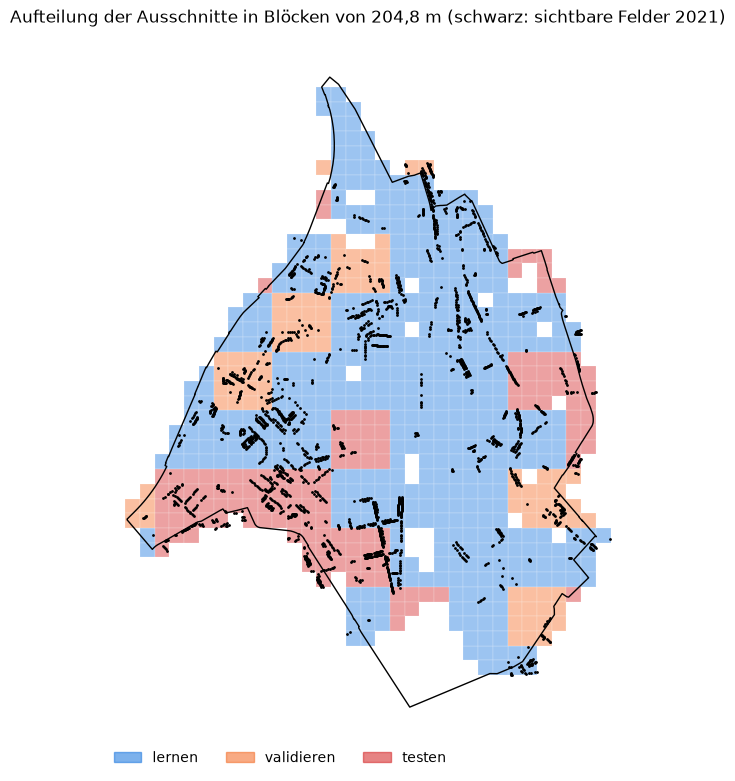

In [9]:
# Karte: jeder Ausschnitt als Quadrat, gefärbt nach seiner Gruppe; dazu die sichtbaren Felder als Punkte
quadrate = gpd.GeoDataFrame(aufteilung, crs=CRS, geometry=[box(i * KACHEL_M, j * KACHEL_M, (i + 1) * KACHEL_M, (j + 1) * KACHEL_M)
                                                           for i, j in zip(aufteilung.i, aufteilung.j)])
farben = {"lernen": "#257de0", "validieren": "#f47230", "testen": "#d63031"}   # Projektfarben der drei Gruppen
fig, ax = plt.subplots(figsize=(8, 9))
for gruppe, farbe in farben.items():                               # je Gruppe eine Ebene
    quadrate[quadrate.gruppe == gruppe].plot(ax=ax, color=farbe, alpha=0.45, edgecolor="white", linewidth=0.3)
ax.scatter(sichtbar_2021.x, sichtbar_2021.y, s=1, color="black")   # sichtbare Felder
gpd.read_file(VERARB / "gebiet.geojson").boundary.plot(ax=ax, color="black", linewidth=1)   # Umriss des Gebiets
from matplotlib.patches import Patch                               # Legendeneinträge für Flächen
ax.legend(handles=[Patch(color=farbe, alpha=0.6, label=gruppe) for gruppe, farbe in farben.items()],
          loc="upper left", bbox_to_anchor=(0, 0), frameon=False, ncol=3)
ax.set_axis_off()
ax.set_title("Aufteilung der Ausschnitte in Blöcken von 204,8 m (schwarz: sichtbare Felder 2021)")
fig.savefig(ABB / "02_aufteilung.png", dpi=130, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Jedes Quadrat ist ein Ausschnitt von 51,2 m; 4 × 4 davon bilden einen Block und haben dieselbe Farbe. Die roten Blöcke sind über das Gebiet verteilt und werden bis zur Auswertung nicht angesehen. Weisse Stellen im Gebiet wurden im Werkzeug nicht gezeigt (keine Strasse, kein DAV-Feld).

## Was wir gesehen haben

- Die Aufteilung steht fest, bevor ein Netz gelernt hat. Sie gilt für beide Versuche (Bild 2021 und Bild 2024/25).
- Die Gruppen sind nach Blöcken und nach Feldern ähnlich gross wie geplant (Tabelle in Abschnitt 2).

## Wie es weitergeht

Notebook 03 misst in den **Lernblöcken**, wie weit die Ringe auseinanderstehen, und leitet daraus die Platzmasse ab. Die Testblöcke bleiben dabei unberührt.